In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler

# 1. Load and Clean Data
file_path = '/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv'
df = pd.read_csv(file_path)

df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm', 'RISK_MM'], errors='ignore')
df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})

for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

compass_points = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
angles = np.arange(0, 360, 22.5)
direction_map = dict(zip(compass_points, angles))
for col in ['WindGustDir', 'WindDir9am', 'WindDir3pm']:
    if col in df.columns:
        df[col + '_sin'] = np.sin(np.radians(df[col].map(direction_map)))
        df[col + '_cos'] = np.cos(np.radians(df[col].map(direction_map)))
        df = df.drop(columns=[col])

df_clean = pd.get_dummies(df, columns=['Location'], drop_first=True)

train_mask = df_clean['Date'] < '2015-01-01'
test_mask = df_clean['Date'] >= '2015-01-01'

features = [col for col in df_clean.columns if col not in ['RainTomorrow', 'Date']]
X = df_clean[features]
y = df_clean['RainTomorrow']

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

print(f"Data ready. Train: {X_train.shape}, Test: {X_test.shape}")

Mounted at /content/drive
Data ready. Train: (98988, 68), Test: (43205, 68)


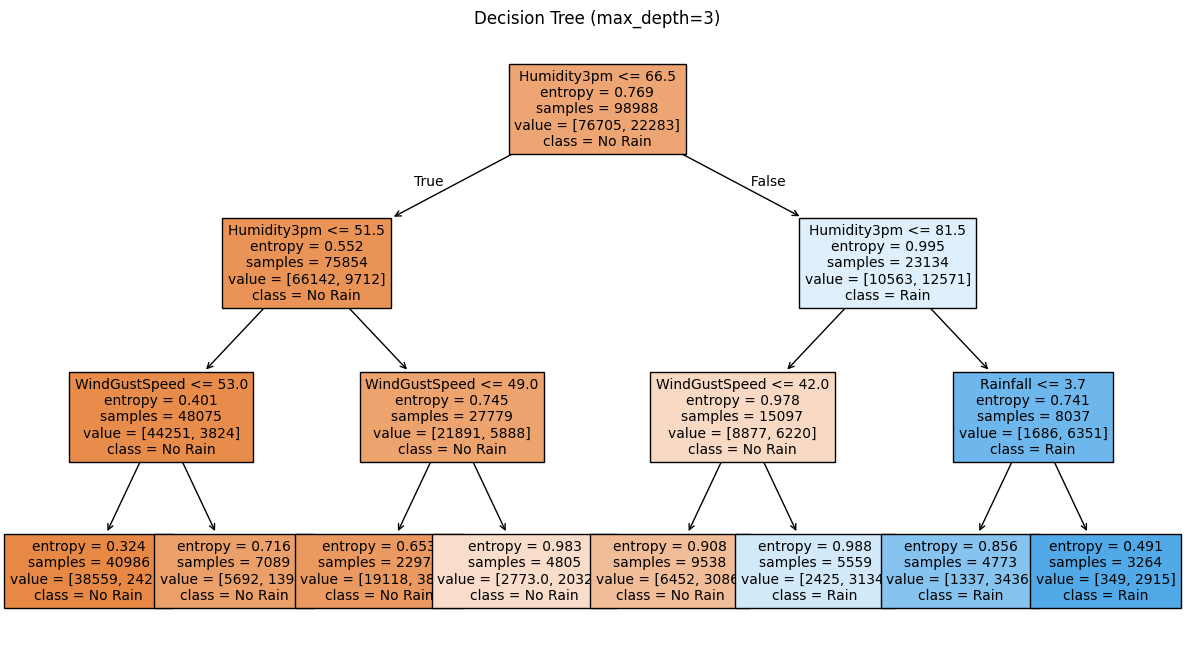

In [2]:
# Fit tree3
tree3 = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42)
tree3.fit(X_train, y_train)

# Plot
plt.figure(figsize=(15, 8))
plot_tree(tree3, feature_names=X_train.columns, class_names=['No Rain', 'Rain'], filled=True, fontsize=10)
plt.title('Decision Tree (max_depth=3)')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/tree_depth3.png')
plt.show()

**Purpose:**
This cell trains a basic Decision Tree Classifier and visualizes its structure.

**Train the Tree:** It fits a DecisionTreeClassifier with a max_depth of 3 and criterion='entropy'. Restricting the depth to 3 keeps the tree simple so it is easy to interpret.

**Plot the Tree:** It uses plot_tree to draw the branches, showing the split conditions (e.g., Humidity3pm <= 66.5), the entropy at each node, and the final classification (No Rain vs. Rain).

**Save:** The diagram is saved to the outputs folder as tree_depth3.png.

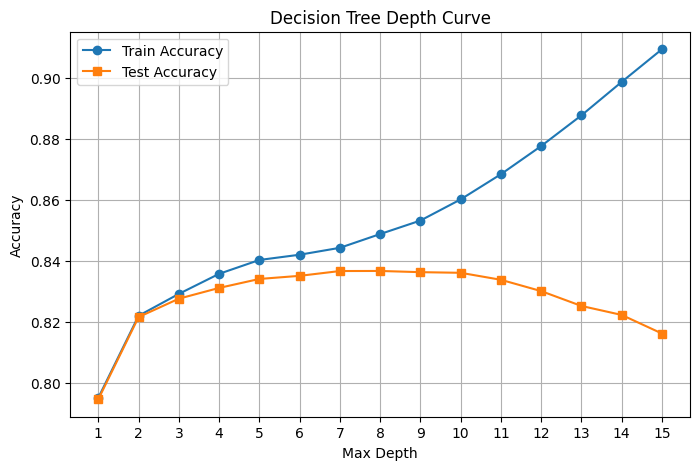

In [3]:
depth_results = []
depths = range(1, 16)

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, criterion='entropy', random_state=42)
    tree.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, tree.predict(X_train))
    test_acc = accuracy_score(y_test, tree.predict(X_test))

    depth_results.append({'Depth': depth, 'Train Accuracy': train_acc, 'Test Accuracy': test_acc})

depth_df = pd.DataFrame(depth_results)

# Plot Depth Curve
plt.figure(figsize=(8, 5))
plt.plot(depth_df['Depth'], depth_df['Train Accuracy'], marker='o', label='Train Accuracy')
plt.plot(depth_df['Depth'], depth_df['Test Accuracy'], marker='s', label='Test Accuracy')
plt.title('Decision Tree Depth Curve')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/depth_curve.png')
plt.show()

**Purpose:**
This cell generates the Depth Curve to find where the Decision Tree starts to overfit.

**Loop (Depth 1 to 15):** It trains a separate Decision Tree for every depth from 1 to 15.

**Evaluate:** For each tree, it calculates the Accuracy on both the Training set and the Test set.

**Plot:** It plots both accuracies on a single graph. As the depth increases, the Training accuracy keeps rising (the model memorizes the data), but the Test accuracy eventually peaks and drops. That drop is the visual sign of overfitting. The chart is saved to outputs/depth_curve.png.

In [4]:
# Exam Skill: Entropy and Information Gain functions
def entropy(y):
    # Calculate the entropy of a target array
    p1 = np.mean(y)
    if p1 == 0 or p1 == 1:
        return 0
    return -p1 * np.log2(p1) - (1 - p1) * np.log2(1 - p1)

def information_gain(y_parent, y_left, y_right):
    # Calculate weighted information gain
    n = len(y_parent)
    n_left = len(y_left)
    n_right = len(y_right)

    ig = entropy(y_parent) - (n_left/n) * entropy(y_left) - (n_right/n) * entropy(y_right)
    return ig

# Calculate IG for the root split (Humidity3pm <= 66.5)
threshold = 66.5
left_mask = X_train['Humidity3pm'] <= threshold
right_mask = X_train['Humidity3pm'] > threshold

ig_root = information_gain(y_train, y_train[left_mask], y_train[right_mask])
print(f"Information Gain for root split (Humidity3pm <= 66.5): {ig_root:.4f}")

# Check Pressure9am at its median
median_pressure = X_train['Pressure9am'].median()
left_mask_p = X_train['Pressure9am'] <= median_pressure
right_mask_p = X_train['Pressure9am'] > median_pressure

ig_pressure = information_gain(y_train, y_train[left_mask_p], y_train[right_mask_p])
print(f"Information Gain for Pressure9am (<= {median_pressure:.1f}): {ig_pressure:.4f}")

Information Gain for root split (Humidity3pm <= 66.5): 0.1139
Information Gain for Pressure9am (<= 1017.6): 0.0216


**Purpose:**
This cell performs the Exam Skill: manually calculating Entropy and Information Gain from scratch to understand how the Decision Tree chooses its splits.

**entropy(y):** Calculates the uncertainty of a target array using the formula
−
p
log
⁡
2
(
p
)
−
(
1
−
p
)
log
⁡
2
(
1
−
p
)
−plog
2
​
 (p)−(1−p)log
2
​
 (1−p). If a node is pure (all rain or all no-rain), entropy is 0.

**information_gain(...):** Calculates the difference between the parent's entropy and the weighted average entropy of the two child nodes.

**Root Split Check:** It calculates the Information Gain for the tree's actual root split (Humidity3pm <= 66.5), which is 0.1139.

**Comparison Check:** It then calculates the Information Gain for a competing split on Pressure9am. That gain is only 0.0216.

**Conclusion:** The math proves the tree chose the right split, because Humidity3pm provides a much larger reduction in uncertainty than Pressure9am.



In [5]:
results_trees = {}

# 1. Tree (Depth 3)
results_trees['Decision Tree (Depth 3)'] = {
    'Accuracy': accuracy_score(y_test, tree3.predict(X_test)),
    'F1-Score': f1_score(y_test, tree3.predict(X_test))
}

# 2. Random Forest (Bagging)
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
results_trees['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'F1-Score': f1_score(y_test, y_pred_rf)
}

# 3. Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
results_trees['Gradient Boosting'] = {
    'Accuracy': accuracy_score(y_test, y_pred_gb),
    'F1-Score': f1_score(y_test, y_pred_gb)
}

print(pd.DataFrame(results_trees).T)

                         Accuracy  F1-Score
Decision Tree (Depth 3)  0.827613  0.513584
Random Forest            0.848605  0.577700
Gradient Boosting        0.844393  0.567903


**Purpose:**

This cell trains three different tree-based models and compares their performance to show the power of ensemble methods.

**Decision Tree (Depth 3):** The simple, single tree from Part A. It serves as the baseline.

**Random Forest (Bagging):** Trains 100 independent trees on random subsets of the data and averages their predictions. This reduces variance and prevents overfitting.

**Gradient Boosting:** Trains 100 trees sequentially, where each new tree focuses on correcting the errors of the previous trees. This reduces bias.

**Output:** Prints a results_trees table comparing Accuracy and F1-score, proving that both ensembles beat the single decision tree.



/tmp/ipykernel_2945/2349546549.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')


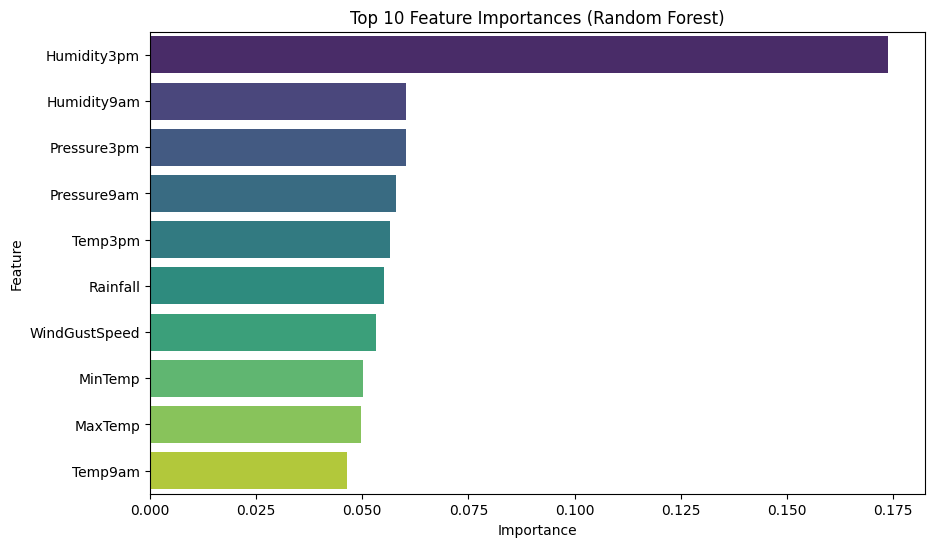

In [6]:
importances = rf.feature_importances_
feature_names = X_train.columns

# Create DataFrame
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False).head(10)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/feature_importance.png')
plt.show()

**Purpose:**

This cell extracts and visualizes the most important features from the trained Random Forest model.

**Extract Importances:** It pulls the feature_importances_ attribute directly from the trained Random Forest (rf). This tells us how much each feature contributed to reducing impurity across all the trees.

**Sort and Filter:** It creates a DataFrame, sorts the features from most important to least important, and keeps only the top 10.

**Plot:** It creates a horizontal bar chart showing the top 10 features. This allows a forecaster to visually confirm whether the model is relying on sensible weather variables (like Humidity and Pressure) rather than random noise. The chart is saved as feature_importance.png

**Exam Skill: Entropy and Information Gain**

**Root Split:** The tree chose Humidity3pm <= 66.5 as the top split. The information gain for this split is 0.1139.

**Comparison:** We compared this to a split on Pressure9am at its median. The information gain for that split was only 0.0216.

**Conclusion:** The tree correctly chose Humidity3pm because it resulted in a much larger reduction in uncertainty (higher information gain) than Pressure9am.

**Written Answer: Trees and Ensembles**

**At what depth did the tree start to overfit?** Looking at the Depth Curve, the single tree started to overfit at depth 7 or 8. After depth 7, the training accuracy continued to rise (approaching 1.0), but the test accuracy began to drop. This means the model was memorizing the training data rather than learning general patterns.

**Why a random forest beats one tree:** A Random Forest (bagging) builds many deep decision trees using random subsets of data and features. It then averages their predictions. This reduces the variance of the model. A single decision tree is very sensitive to small changes in the data; the forest smooths out these errors, preventing overfitting and achieving a higher test accuracy.

**Feature Importance:** The chart shows that Humidity3pm, Humidity9am, and Pressure3pm are the most important features. This matches what a forecaster would expect—high afternoon humidity and low pressure are strong indicators of incoming rain.